<a href="https://colab.research.google.com/github/aalitorres/002_A2026_Artificial_Intelligence/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Malaria-Infected Cell Classification Using a Custom CNN

## 1. Introduction

This project focuses on developing a Custom Convolutional Neural Network (CNN) to classify microscopic red blood cell images into two categories: Parasitized and Uninfected.

The model uses the NIH Malaria Cell Images Dataset and TensorFlow/Keras to learn visual patterns associated with malaria-infected cells.

**Dataset:** NIH Malaria Cell Images Dataset.

**Model:** Custom Convolutional Neural Network.

**Framework:** TensorFlow and Keras.

**Objective:** To develop and evaluate a CNN capable of classifying microscopic red blood cell images as parasitized or uninfected.

## 2. Importing Libraries

The libraries required for image processing, data manipulation, visualization, CNN development, and model evaluation are imported.

In [3]:
# Import required libraries

import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

## 3. Reproducibility

Random seeds are established to improve the reproducibility of the experiments.

In [ ]:
# Set random seeds

tf.random.set_seed(42)
np.random.seed(42)

## 4. Dataset Acquisition

The NIH Malaria Cell Images Dataset is downloaded from the National Library of Medicine repository. It contains microscopic images of red blood cells classified into two categories: Parasitized and Uninfected.

In [ ]:
# Download the NIH Malaria Cell Images Dataset

dataset_url = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"
zip_path = "/content/cell_images.zip"
extract_path = "/content/malaria_dataset"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(dataset_url, zip_path)

print("Dataset downloaded successfully.")

Dataset downloaded successfully.


In [ ]:
# Extract the dataset

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [ ]:
# Explore the dataset directory

for root, dirs, files in os.walk(extract_path):
    print(root, "->", len(files), "files")

/content/malaria_dataset -> 0 files
/content/malaria_dataset/cell_images -> 0 files
/content/malaria_dataset/cell_images/Uninfected -> 13780 files
/content/malaria_dataset/cell_images/Parasitized -> 13780 files


## 5. Dataset Exploration

The dataset contains two categories of microscopic red blood cell images: Parasitized and Uninfected.

A sample of images from each category is visualized to inspect their appearance and verify the dataset structure.

In [ ]:
# Define dataset directories

parasitized_dir = os.path.join(extract_path, "cell_images", "Parasitized")
uninfected_dir = os.path.join(extract_path, "cell_images", "Uninfected")

# Count images in each category

parasitized_images = os.listdir(parasitized_dir)
uninfected_images = os.listdir(uninfected_dir)

print("Parasitized images:", len(parasitized_images))
print("Uninfected images:", len(uninfected_images))
print("Total images:", len(parasitized_images) + len(uninfected_images))

Parasitized images: 13780
Uninfected images: 13780
Total images: 27560


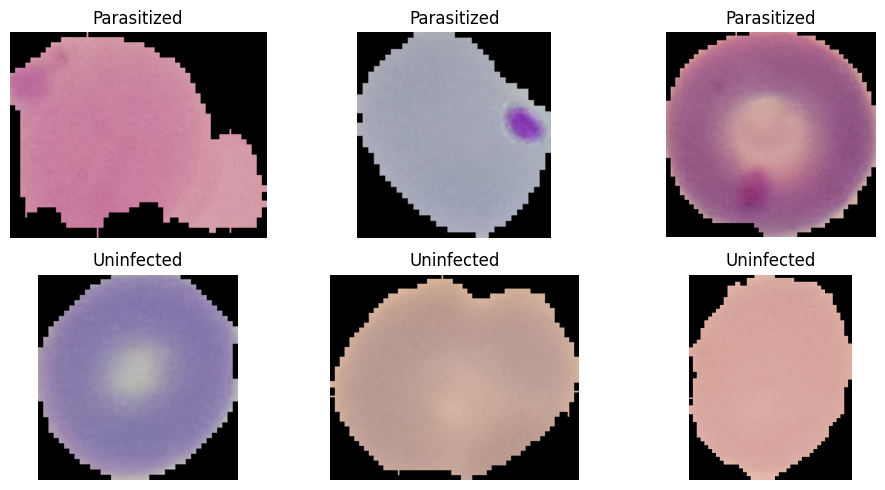

In [ ]:
# Display sample images from both classes

plt.figure(figsize=(10, 5))

for i in range(3):
    img = Image.open(os.path.join(parasitized_dir, parasitized_images[i]))
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title("Parasitized")
    plt.axis("off")

for i in range(3):
    img = Image.open(os.path.join(uninfected_dir, uninfected_images[i]))
    plt.subplot(2, 3, i + 4)
    plt.imshow(img)
    plt.title("Uninfected")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Data Cleaning

The images are checked to identify corrupted or unreadable files. Valid images are retained for the classification process.

In [ ]:
# Check image integrity

def check_images(directory):
    valid_images = []
    corrupted_images = []

    for filename in os.listdir(directory):
        filepath = os.path.join(directory, filename)

        try:
            with Image.open(filepath) as img:
                img.verify()
            valid_images.append(filename)

        except Exception:
            corrupted_images.append(filename)

    return valid_images, corrupted_images


# Check both categories

valid_parasitized, corrupted_parasitized = check_images(parasitized_dir)
valid_uninfected, corrupted_uninfected = check_images(uninfected_dir)

print("Parasitized:")
print("Valid images:", len(valid_parasitized))
print("Corrupted images:", len(corrupted_parasitized))

print("\nUninfected:")
print("Valid images:", len(valid_uninfected))
print("Corrupted images:", len(corrupted_uninfected))

print("\nTotal valid images:",
      len(valid_parasitized) + len(valid_uninfected))

Parasitized:
Valid images: 13779
Corrupted images: 1

Uninfected:
Valid images: 13779
Corrupted images: 1

Total valid images: 27558


## 7. Image Preprocessing

All valid images are resized to a uniform dimension of 224 × 224 pixels and converted to RGB format.

Pixel values are normalized from the original range of [0, 255] to [0, 1] to facilitate neural network training.

In [ ]:
# Prepare image paths and labels using only valid images

image_paths = []
image_labels = []

# Label 0: Parasitized
for filename in valid_parasitized:
    image_paths.append(os.path.join(parasitized_dir, filename))
    image_labels.append(0)

# Label 1: Uninfected
for filename in valid_uninfected:
    image_paths.append(os.path.join(uninfected_dir, filename))
    image_labels.append(1)

print("Total valid images:", len(image_paths))
print("Total labels:", len(image_labels))

Total valid images: 27558
Total labels: 27558


In [ ]:
# Define image preprocessing function

IMG_SIZE = 224

def preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize images to 224 x 224
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    # Normalize pixel values to [0, 1]
    image = image / 255.0

    return image, label

In [ ]:
# Verify preprocessing with one sample image

sample_image, sample_label = preprocess_image(
    image_paths[0],
    image_labels[0]
)

print("Image shape:", sample_image.shape)
print("Minimum pixel value:", tf.reduce_min(sample_image).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_image).numpy())
print("Image label:", sample_label)

Image shape: (224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.8605944
Image label: 0


## 8. Dataset Splitting

The dataset is divided into training (80%) and testing (20%) subsets using stratified sampling to preserve the class distribution in both subsets.

In [ ]:
# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    image_paths,
    image_labels,
    test_size=0.20,
    random_state=42,
    stratify=image_labels
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training images: 22046
Testing images: 5512

Training class distribution:
0    11023
1    11023
Name: count, dtype: int64

Testing class distribution:
0    2756
1    2756
Name: count, dtype: int64


## 9. TensorFlow Dataset Preparation

The training and testing image paths are converted into TensorFlow datasets. Images are resized, normalized, batched, and prepared for model training and evaluation.

In [ ]:
# Define batch size

BATCH_SIZE = 32

# Create training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = train_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.shuffle(
    buffer_size=1000,
    seed=42
)

train_dataset = train_dataset.batch(BATCH_SIZE)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)


# Create testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = test_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)


print("Training and testing datasets are ready.")

Training and testing datasets are ready.


In [ ]:
# Verify dataset batches

for images, labels in train_dataset.take(1):
    print("Training batch image shape:", images.shape)
    print("Training batch label shape:", labels.shape)

for images, labels in test_dataset.take(1):
    print("Testing batch image shape:", images.shape)
    print("Testing batch label shape:", labels.shape)

Training batch image shape: (32, 224, 224, 3)
Training batch label shape: (32,)
Testing batch image shape: (32, 224, 224, 3)
Testing batch label shape: (32,)


## 10. Custom CNN Architecture

A custom Convolutional Neural Network (CNN) is developed from scratch to classify malaria-infected and uninfected red blood cell images.

The architecture consists of convolutional layers, max-pooling layers, dropout regularization, and fully connected layers.

The final sigmoid activation function produces a probability for binary classification.

In [ ]:
# Build the Custom CNN model

model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Feature extraction and classification
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

## 11. Model Compilation

The CNN model is compiled using the Adam optimizer and Binary Crossentropy loss function. Accuracy is selected as the evaluation metric during training.

In [ ]:
# Compile the CNN model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")

Model compiled successfully.


## 12. Training and Validation Preparation

A validation subset is created from the original training data to monitor model performance during training. The testing dataset remains separate and is reserved for final evaluation.

In [ ]:
# Split the original training data into training and validation sets

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training images:", len(X_train_final))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 17636
Validation images: 4410
Testing images: 5512


In [ ]:
# Function to create TensorFlow datasets

def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Create final datasets

train_dataset = create_dataset(
    X_train_final, y_train_final, training=True
)

val_dataset = create_dataset(
    X_val, y_val
)

test_dataset = create_dataset(
    X_test, y_test
)

print("All datasets are ready.")

All datasets are ready.


## 13. Model Training

The CNN is trained using the training dataset and monitored using the validation dataset.

Early Stopping is implemented to prevent unnecessary training and reduce overfitting. The weights from the best validation loss are restored.

In [ ]:
# Configure Early Stopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train the CNN model

EPOCHS = 20

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20
552/552 ━━━━━━━━━━━━━━━━━━━━ 61s 86ms/step - accuracy: 0.8147 - loss: 0.4099 - val_accuracy: 0.9413 - val_loss: 0.1977
Epoch 2/20
552/552 ━━━━━━━━━━━━━━━━━━━━ 35s 62ms/step - accuracy: 0.9331 - loss: 0.2175 - val_accuracy: 0.9494 - val_loss: 0.1681
Epoch 3/20
552/552 ━━━━━━━━━━━━━━━━━━━━ 41s 63ms/step - accuracy: 0.9343 - loss: 0.2052 - val_accuracy: 0.9293 - val_loss: 0.1809
Epoch 4/20
552/552 ━━━━━━━━━━━━━━━━━━━━ 35s 61ms/step - accuracy: 0.9369 - loss: 0.1992 - val_accuracy: 0.9535 - val_loss: 0.1614
Epoch 5/20
552/552 ━━━━━━━━━━━━━━━━━━━━ 43s 64ms/step - accuracy: 0.9412 - loss: 0.1863 - val_accuracy: 0.9519 - val_loss: 0.1511
Epoch 6/20
552/552 ━━━━━━━━━━━━━━━━━━━━ 35s 62ms/step - accuracy: 0.9434 - loss: 0.1784 - val_accuracy: 0.9567 - val_loss: 0.1453
Epoch 7/20
552/552 ━━━━━━━━━━━━━━━━━━━━ 42s 64ms/step - accuracy: 0.9466 - loss: 0.1732 - val_accuracy: 0.9594 - val_loss: 0.1378
Epoch 8/20
552/552 ━━━━━━━━━━━━━━━━━━━━ 36s 64ms/step - accuracy: 0.9498 - loss: 0.1672 - 

## 14. Training Performance Visualization

The training and validation accuracy and loss are visualized across epochs to analyze the learning process and identify possible signs of overfitting.

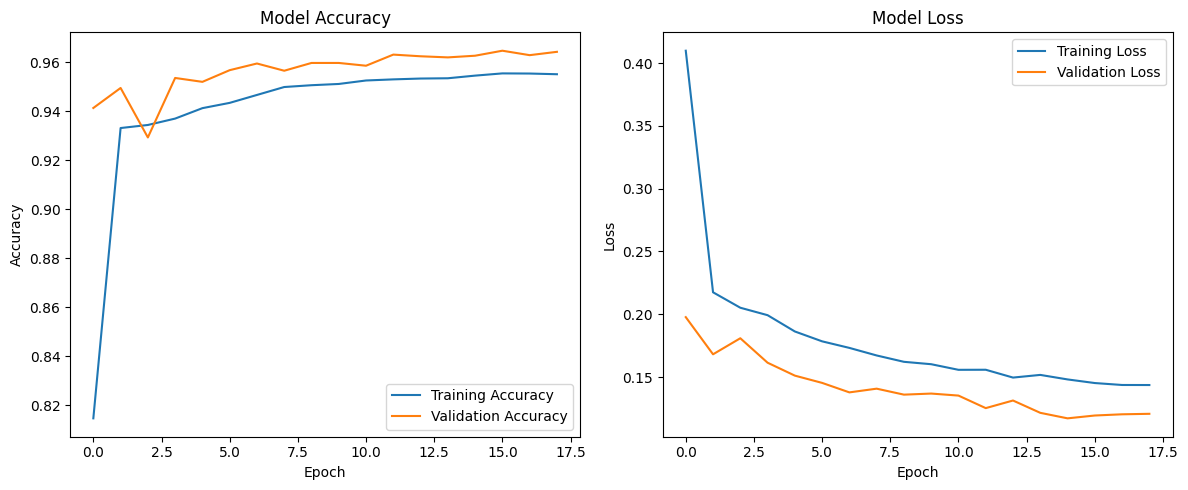

In [ ]:
# Plot training and validation accuracy

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 15. Model Evaluation

The trained CNN is evaluated using the independent testing dataset. Accuracy, sensitivity, specificity, classification report, and confusion matrix are calculated to assess its classification performance.

In [ ]:
# Evaluate model on the testing dataset

test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

173/173 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - accuracy: 0.9579 - loss: 0.1342
Test Loss: 0.13422399759292603
Test Accuracy: 0.9579100012779236
Test Accuracy (%): 95.79100012779236


## 16. Classification Metrics and Confusion Matrix

Sensitivity (Recall) measures the model's ability to correctly identify parasitized cells.

Specificity measures the model's ability to correctly identify uninfected cells.

A confusion matrix and classification report are generated to analyze the model's performance across both classes.

173/173 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step
Classification Report:

              precision    recall  f1-score   support

 Parasitized     0.9828    0.9321    0.9568      2756
  Uninfected     0.9355    0.9837    0.9590      2756

    accuracy                         0.9579      5512
   macro avg     0.9591    0.9579    0.9579      5512
weighted avg     0.9591    0.9579    0.9579      5512

Sensitivity: 0.9321480406386067
Sensitivity (%): 93.21480406386067

Specificity: 0.9836719883889695
Specificity (%): 98.36719883889695


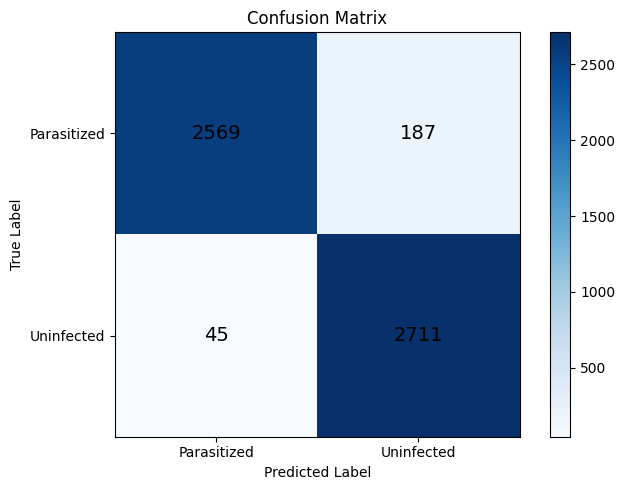

In [ ]:
# Generate predictions on the testing dataset

y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

y_prob = model.predict(test_dataset)

# Convert probabilities into binary predictions
y_pred = (y_prob.ravel() >= 0.5).astype(int)


# Generate classification report

print("Classification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Parasitized", "Uninfected"],
    digits=4
))


# Calculate sensitivity and specificity

from sklearn.metrics import recall_score

sensitivity = recall_score(
    y_true, y_pred, pos_label=0
)

specificity = recall_score(
    y_true, y_pred, pos_label=1
)

print("Sensitivity:", sensitivity)
print("Sensitivity (%):", sensitivity * 100)

print("\nSpecificity:", specificity)
print("Specificity (%):", specificity * 100)


# Generate confusion matrix

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], ["Parasitized", "Uninfected"])
plt.yticks([0, 1], ["Parasitized", "Uninfected"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            color="black",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

## 17. Model Saving

The trained CNN model is saved in HDF5 (.h5) format, including its architecture, trained weights, and compilation configuration. This allows the model to be loaded and used for future predictions without retraining.

In [ ]:
# Save the trained CNN model

model_path = "/content/malaria_cnn_model.h5"

model.save(model_path)

print("Model saved successfully at:", model_path)

Model saved successfully at: /content/malaria_cnn_model.h5


In [ ]:
# Verify saved model

print("Model file exists:", os.path.exists(model_path))
print("Model file size (MB):", round(os.path.getsize(model_path) / (1024 * 1024), 2))

Model file exists: True
Model file size (MB): 1.21


In [4]:
# Import TensorFlow

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [5]:
# Load the trained CNN model

model = tf.keras.models.load_model(
    "/content/malaria_cnn_model.h5"
)

print("Model loaded successfully.")

Model loaded successfully.


In [6]:
# Verify loaded model

print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

Model input shape: (None, 224, 224, 3)
Model output shape: (None, 1)


## 18. External Validation

Five individual red blood cell images from the independent PlasmoCount dataset are used to evaluate the trained CNN.

The images are resized to 224 × 224 pixels and normalized before classification. Model predictions are compared with their original labels.

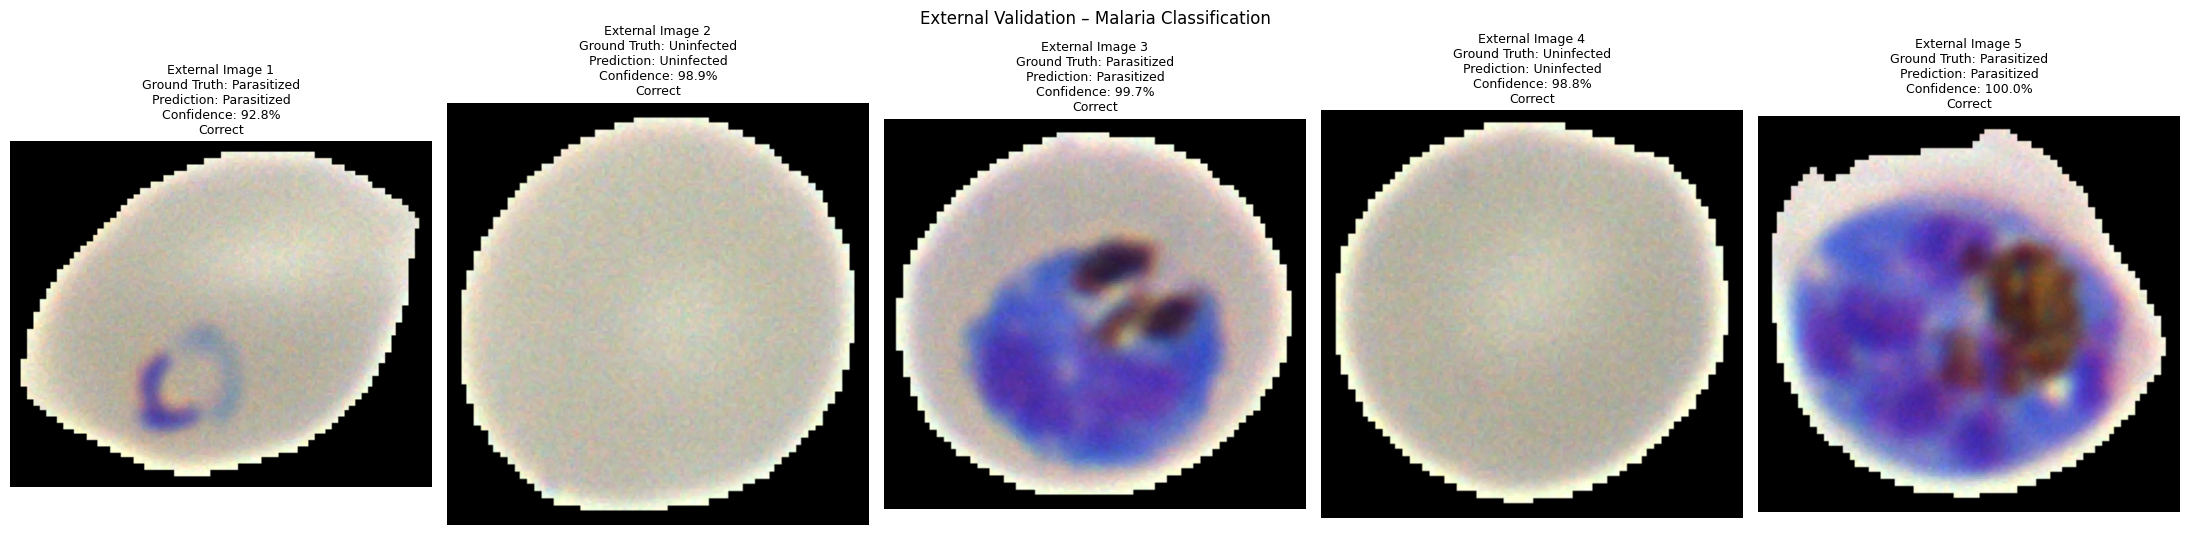

,Image,Ground Truth,Prediction,Confidence (%),Correct
0,1,Parasitized,Parasitized,92.839996,True
1,2,Uninfected,Uninfected,98.919998,True
2,3,Parasitized,Parasitized,99.699997,True
3,4,Uninfected,Uninfected,98.790001,True
4,5,Parasitized,Parasitized,100.000000,True


Correct predictions: 5/5


In [9]:
# External image classification

import os
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image

# Extract external images
with zipfile.ZipFile("external_5.zip", "r") as zip_ref:
    zip_ref.extractall("/content/external_5")

# Load external image labels
df = pd.read_csv("external_5.csv")

# Define class labels
CLASS_NAMES = {
    0: "Parasitized",
    1: "Uninfected"
}

NAME2ID = {v: k for k, v in CLASS_NAMES.items()}

# Image preprocessing
def preprocess(path):
    image = Image.open(path).convert("RGB")
    image = image.resize((224, 224), Image.Resampling.BILINEAR)

    return np.asarray(image, dtype=np.float32) / 255.0

# Load external images
X = np.stack([
    preprocess(f"/content/external_5/{f}")
    for f in df["file"]
])

# Load trained model
model = tf.keras.models.load_model(
    "/content/malaria_cnn_model.h5",
    compile=False
)

# Generate predictions
predictions = model.predict(X, verbose=0).ravel()

# Display results
results = []

fig, axes = plt.subplots(1, 5, figsize=(22, 6))

for ax, (_, row), probability in zip(axes, df.iterrows(), predictions):

    predicted_label = int(probability >= 0.5)

    confidence = (
        probability if predicted_label == 1
        else 1 - probability
    ) * 100

    ground_truth = row["ground_truth"]
    correct = predicted_label == NAME2ID[ground_truth]

    results.append({
        "Image": row["external_id"],
        "Ground Truth": ground_truth,
        "Prediction": CLASS_NAMES[predicted_label],
        "Confidence (%)": round(confidence, 2),
        "Correct": correct
    })

    ax.imshow(Image.open(
        f"/content/external_5/{row['file']}"
    ))

    ax.axis("off")

    ax.set_title(
        f"External Image {row['external_id']}\n"
        f"Ground Truth: {ground_truth}\n"
        f"Prediction: {CLASS_NAMES[predicted_label]}\n"
        f"Confidence: {confidence:.1f}%\n"
        f"{'Correct' if correct else 'Incorrect'}",
        fontsize=9
    )

plt.suptitle("External Validation – Malaria Classification")
plt.tight_layout()
plt.show()

# Display classification results
results_df = pd.DataFrame(results)

display(results_df)

print(
    f"Correct predictions: "
    f"{results_df['Correct'].sum()}/5"
)